In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from pathlib import Path

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt

def plot_ecg(title, filename, show=True, save=True, y_inputs=None, x_input=None, labels=None):
	"""Plot one or more y-inputs against a shared x-input."""
	if y_inputs is None or x_input is None or labels is None:
		raise ValueError("y_inputs, x_input, and labels are required")
	if len(y_inputs) != len(labels):
		raise ValueError("Provide exactly one label for each y_input")

	plt.figure(figsize=(10, 4))
	for y_input, label in zip(y_inputs, labels):
		plt.plot(x_input, y_input, label=label)

	plt.title(title)
	plt.xlabel('Time (s)')
	plt.ylabel('ECG Signal (mV)')
	plt.legend()
	plt.grid()
	plt.tight_layout()

	if save:
		plot_path = ROOT / filename
		plot_path.parent.mkdir(parents=True, exist_ok=True)
		plt.savefig(plot_path)
	if show:
		plt.show()


# Design filter

In [3]:
# DATASET = Path(__file__).resolve().parent / "ecg_dataset.csv"
# Project root: this notebook lives in py/, but data/ and fig/ belong at the project root.
ROOT = Path.cwd().parent if Path.cwd().name == "py" else Path.cwd()
DATASET_DIR = ROOT / "dataset"  # input CSVs
DATA_DIR = ROOT / "data"  # all generated data files (.npy, .mem, .txt, .json) go here
DATA_DIR.mkdir(exist_ok=True)
DATASET = DATASET_DIR / "ecg_fir_data_full.csv"
FS_HZ = 360
CUTOFF_HZ = 20
NUM_TAPS = 63  # A starting design choice, not an instructor-specified order.
FRAC_BITS = 15
DATA_BITS = 16
ACC_BITS = 40

sample = time_s = clean_mv = clean = noisy = supplied = None

data = np.genfromtxt(DATASET, delimiter=',', names=True, dtype=None, encoding=None)
sample = data['sample']
time_s = data['time_s']
clean_mv = data['clean_ecg_mV']
clean = data['clean_ecg']
noisy = data['noisy_input']

# all columns min and max
print(f"sample: {sample.min()}; {sample.max()}")
print(f"time_s: {time_s.min()}; {time_s.max()}")
print(f"clean_mv: {clean_mv.min()}; {clean_mv.max()}")
print(f"clean: {clean.min()}; {clean.max()}")
print(f"noisy: {noisy.min()}; {noisy.max()}")

sample: 0; 1023
time_s: 0.0; 2.841667
clean_mv: -0.645; 0.96
clean: -3777.1898; 14512.5012
noisy: -7525; 16384


Estimated Fs: 360.00 Hz
Plotting clean and noisy ECG signals...
Filtered ECG signal plotted and saved.
Row count: 1024, Fs: 360.00, Taps: 63, Order: 62, Delay: 31 samples


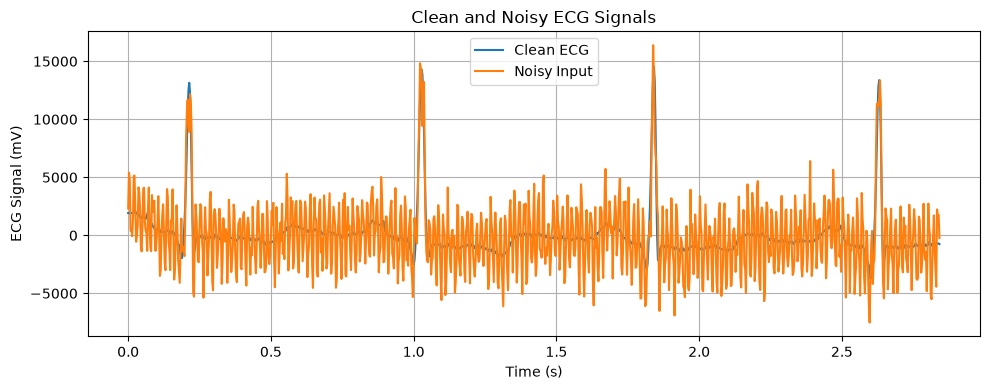

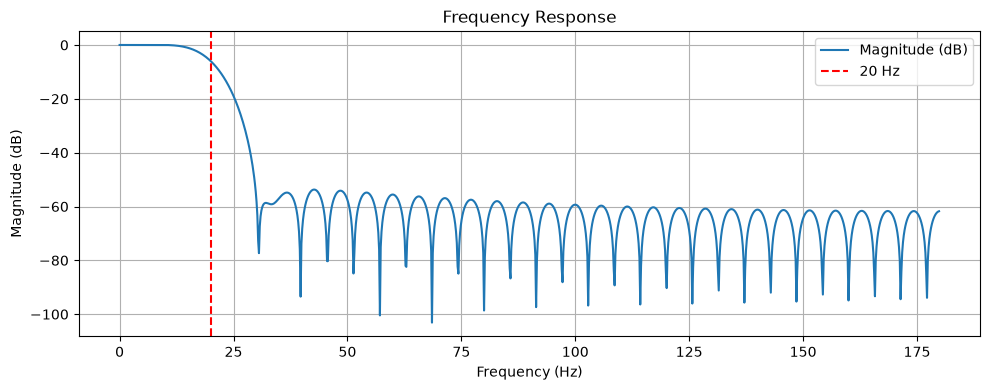

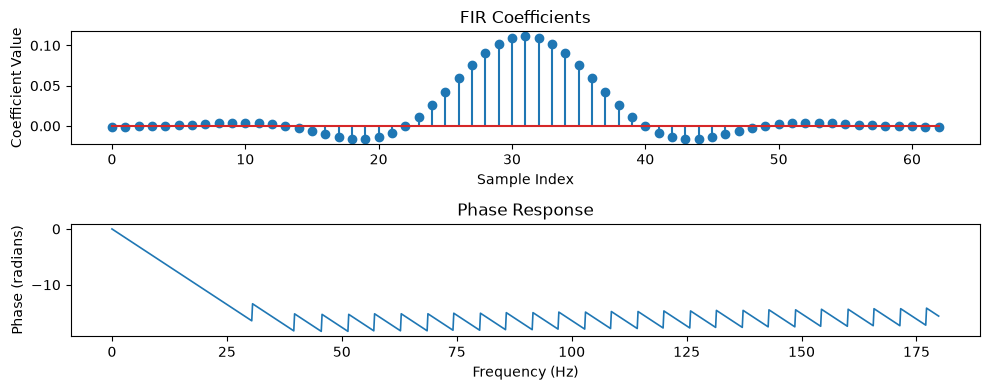

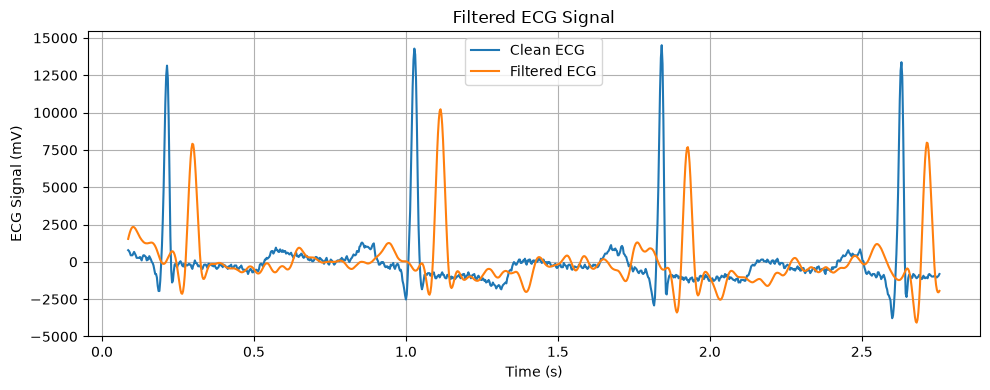

In [4]:
FS_EST = (len(time_s) - 1) / (time_s[-1] - time_s[0])
print(f"Estimated Fs: {FS_EST:.2f} Hz")

print("Plotting clean and noisy ECG signals...")
plot_ecg(
	title="Clean and Noisy ECG Signals",
	filename="fig/ecg_signals.png",
	y_inputs=[clean, noisy],
	x_input=time_s,
	labels=['Clean ECG', 'Noisy Input'],
    show=False,
)

h = signal.firwin(NUM_TAPS, CUTOFF_HZ, window="hamming", fs=FS_HZ)

w, H = signal.freqz(h, worN=1024, fs=FS_HZ)
plt.figure(figsize=(10, 4))
plt.plot(w, 20 * np.log10(np.abs(H)), label='Magnitude (dB)')
plt.axvline(CUTOFF_HZ, color='r', linestyle='--', label=f'{CUTOFF_HZ} Hz')
plt.title('Frequency Response')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude (dB)')
plt.legend()
plt.grid()
plt.tight_layout()
# plt.show()
save_path = ROOT / "fig" / "frequency_response.png"
save_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(save_path)

# coefficients and phase
plt.figure(figsize=(10, 4))
plt.subplot(2, 1, 1)
plt.stem(h)
plt.title('FIR Coefficients')
plt.xlabel('Sample Index')
plt.ylabel('Coefficient Value')
plt.subplot(2, 1, 2)
plt.plot(w, np.unwrap(np.angle(H)), lw=1.2)
plt.title('Phase Response')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Phase (radians)')
plt.tight_layout()
# plt.show()
plot_path = ROOT / "fig" / "coefficients_phase.png"
plot_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(plot_path)

filtered_output = signal.lfilter(h, 1, noisy)

delay = (NUM_TAPS - 1) // 2
filtered_output = filtered_output[delay:-delay]

coeff_path = DATA_DIR / "coefficients.npy"
np.save(coeff_path, h)
coeff_path = DATA_DIR / "noisy_input.npy"
np.save(coeff_path, noisy)
# CHECK: 1024 rows, Fs approximately 360, 63 taps, order 62, delay 31 samples.
plot_ecg(
    title="Filtered ECG Signal",
    filename="fig/filtered_ecg_signal.png",
    y_inputs=[clean[delay:-delay], filtered_output],
    x_input=time_s[delay:-delay],
    labels=['Clean ECG', 'Filtered ECG'],
    show=False,
)
print("Filtered ECG signal plotted and saved.")
print(f"Row count: {len(time_s)}, Fs: {FS_EST:.2f}, Taps: {NUM_TAPS}, Order: {NUM_TAPS-1}, Delay: {delay} samples")
# QUESTION: Why is the supplied filtered_output not automatically your RTL oracle?


# Fixed reference

In [5]:
h = np.load(DATA_DIR / "coefficients.npy")
noisy_input = np.load(DATA_DIR / "noisy_input.npy")

h_quantized = np.round(h * (2 ** FRAC_BITS)).astype(np.int16)

h_reconstructed = h_quantized / (2 ** FRAC_BITS)
reconstructed_w, reconstructed_H = signal.freqz(h_reconstructed, worN=1024, fs=FS_HZ)

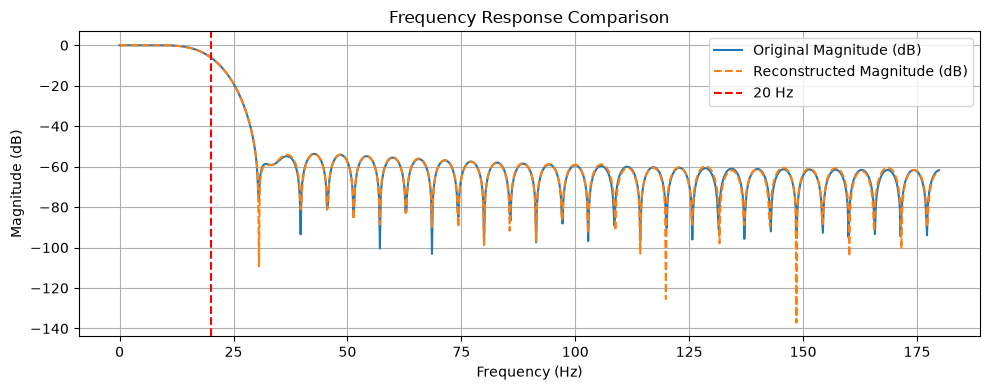

In [6]:
plt.figure(figsize=(10, 4))
plt.plot(w, 20 * np.log10(np.abs(H)), label='Original Magnitude (dB)')
plt.plot(reconstructed_w, 20 * np.log10(np.abs(reconstructed_H)), label='Reconstructed Magnitude (dB)', linestyle='--')
plt.axvline(CUTOFF_HZ, color='r', linestyle='--', label=f'{CUTOFF_HZ} Hz')
plt.title('Frequency Response Comparison')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude (dB)')
plt.legend()
plt.grid()
plt.tight_layout()
save_path = ROOT / "fig" / "frequency_response_comparison.png"
save_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(save_path)

In [7]:
# Helper: write signed ints as 4-digit hex words (two's complement), one per line, no header.
def write_mem(path, values):
    with open(path, 'w') as f:
        for value in values:
            f.write(format(int(value) & 0xffff, '04x') + '\n')

# TODO 4 + TODO 5: bit-exact FIR model. Input list in, (clamped outputs, full sums) out.
def fir_model(input_signal):
    history = [0] * NUM_TAPS
    output_signal = []
    history_total = []
    for sample in input_signal:
        history.insert(0, int(sample))  # NEW input at history[0]
        history.pop()  # Remove the oldest sample to maintain the history length
        total = 0
        for j in range(NUM_TAPS):
            total += int(history[j]) * int(h_quantized[j])
        history_total.append(total)
        shifted = total >> FRAC_BITS  # Shift the FULL sum right by 15
        clamped = max(min(shifted, 32767), -32768)  # Clamp to [-32768, 32767]
        output_signal.append(clamped)
    return output_signal, history_total

fir_output, history_total = fir_model(noisy_input)
expected_output = fir_output

# print first and last 10 values for verification
print("First 10 outputs:", fir_output[:10])
print("Last 10 outputs:", fir_output[-10:])
print("First 10 full sums:", history_total[:10])
print("Last 10 full sums:", history_total[-10:])

# TODO 6: Check the accumulator bound max_abs_input*sum(abs(c)).
max_abs_input = int(np.abs(noisy_input).max())
sum_abs_coeff = sum(abs(int(c)) for c in h_quantized)
acc_limit = 2 ** (ACC_BITS - 1) - 1
bound_data = max_abs_input * sum_abs_coeff              # bound for the supplied ECG data
bound_design = 2 ** (DATA_BITS - 1) * sum_abs_coeff     # bound for ANY legal 16-bit input
peak_sum = max(abs(t) for t in history_total)           # actual peak on the ECG data
print(f"max|x|={max_abs_input}, sum|c|={sum_abs_coeff}, signed {ACC_BITS}-bit limit={acc_limit}")
print(f"Data bound   : {bound_data}  fits: {bound_data <= acc_limit}")
print(f"Design bound : {bound_design}  fits: {bound_design <= acc_limit}")
print(f"Actual peak  : {peak_sum}")
assert bound_design <= acc_limit

# TODO 7: Write ecg.mem, coeff.mem, expected.mem: one 4-digit hex word per line.
#         Encode negative values using value & 0xffff. Do NOT add CSV headers.
write_mem(DATA_DIR / "ecg.mem", noisy_input)
write_mem(DATA_DIR / "coeff.mem", h_quantized)       # quantized coefficients, not float h
write_mem(DATA_DIR / "expected.mem", expected_output)

# CHECK: input/reference memory = 1024 words; coefficient memory = 63 words.
for name, words in (("ecg.mem", 1024), ("coeff.mem", 63), ("expected.mem", 1024)):
    with open(DATA_DIR / name) as f:
        count = sum(1 for _ in f)
    assert count == words, f"{name}: {count} lines, expected {words}"
print("Memory file line counts OK")

# CHECK: Python (-1 >> 15) is -1 (floor); int(-1/32768) is 0 (truncation toward zero).
print("-1 >> 15 =", -1 >> FRAC_BITS, "| int(-1/32768) =", int(-1 / 2 ** FRAC_BITS))

First 10 outputs: [-2, -7, -10, -9, -6, -2, 4, 9, 16, 26]
Last 10 outputs: [-572, -584, -608, -637, -671, -714, -771, -839, -907, -972]
First 10 full sums: [-62694, -203526, -313548, -274800, -193788, -36509, 156474, 321051, 547059, 876460]
Last 10 full sums: [-18717498, -19110970, -19920144, -20851768, -21968519, -23371262, -25241879, -27460506, -29711282, -31842154]
max|x|=16384, sum|c|=44633, signed 40-bit limit=549755813887
Data bound   : 731267072  fits: True
Design bound : 1462534144  fits: True
Actual peak  : 334915787
Memory file line counts OK
-1 >> 15 = -1 | int(-1/32768) = 0


In [8]:
# TODO 8: Generate impulse, positive/negative step, extreme and random test vectors.
N = 1024
rng = np.random.default_rng(1)

# Worst case for the accumulator: each input sample has the sign of the coefficient it meets.
# The newest sample meets h[0], so at n = NUM_TAPS-1 the stream must be sign(h) reversed.
coeff_signs = [(c > 0) - (c < 0) for c in (int(v) for v in h_quantized)]
worst_case = [s for s in reversed(coeff_signs)] + [0] * (N - NUM_TAPS)

test_signals = {
    "impulse":        [32767] + [0] * (N - 1),
    "positive_step":  [10000] * N,
    "negative_step":  [-10000] * N,
    "extreme_values": [32767, -32768] * (N // 2),
    "random_values":  rng.integers(-32768, 32768, size=N).tolist(),
    "clamp_positive": [32767 * s for s in worst_case],   # drives the output above +32767
    "clamp_negative": [-32767 * s for s in worst_case],  # drives the output below -32768
}

for signal_name, signal_data in test_signals.items():
    assert len(signal_data) == N and all(-32768 <= v <= 32767 for v in signal_data)
    output_signal, sums = fir_model(signal_data)
    clamped_count = sum(1 for t in sums if not -32768 <= (t >> FRAC_BITS) <= 32767)
    write_mem(DATA_DIR / f"{signal_name}_in.mem", signal_data)
    write_mem(DATA_DIR / f"{signal_name}_expected.mem", output_signal)
    # TODO 9: expected output in decimal for the report
    np.savetxt(DATA_DIR / f"{signal_name}_expected_dec.txt", output_signal, fmt="%d")
    print(f"{signal_name:15s} out range [{min(output_signal)}, {max(output_signal)}], clamped samples: {clamped_count}")

impulse         out range [-527, 3642], clamped samples: 0
positive_step   out range [-702, 10700], clamped samples: 0
negative_step   out range [-10701, 701], clamped samples: 0
extreme_values  out range [-283, 1833], clamped samples: 0
random_values   out range [-18519, 14674], clamped samples: 0
clamp_positive  out range [-22482, 32767], clamped samples: 7
clamp_negative  out range [-32768, 22481], clamped samples: 7


In [9]:
# Independent check: the Python-integer loop must equal a NumPy integer convolution.
reference_sums = np.convolve(np.asarray(noisy_input, dtype=np.int64),
                             np.asarray(h_quantized, dtype=np.int64))[:len(noisy_input)]
assert [int(v) for v in reference_sums] == history_total
print("fir_model matches np.convolve (full sums identical)")

# TODO 9: Save expected decimal output and metric definitions for your report.
import json
np.savetxt(DATA_DIR / "expected_decimal.txt", expected_output, fmt="%d")

n = len(noisy_input)
delay = (NUM_TAPS - 1) // 2          # linear-phase group delay: 31 samples
clean_ref = np.asarray(clean, dtype=float)[:n - delay]   # output[n] corresponds to clean[n-31]
fixed_out = np.asarray(fir_output, dtype=float)[delay:]
noisy_ref = np.asarray(noisy_input, dtype=float)[:n - delay]
float_ref = np.convolve(np.asarray(noisy_input, dtype=float), np.asarray(h))[:n]

def mse(a, b):
    return float(np.mean((a - b) ** 2))

def snr_db(ref, est):
    return float(10 * np.log10(np.sum(ref ** 2) / np.sum((ref - est) ** 2)))

metrics = {
    "definitions": {
        "delay_samples": "(NUM_TAPS-1)/2; output[n] aligns with clean[n-delay]",
        "mse_noisy": "mean((noisy[n] - clean[n])^2) over n in [0, N-delay)",
        "mse_filtered": "mean((fixed_output[n+delay] - clean[n])^2) over n in [0, N-delay)",
        "snr_db": "10*log10(sum(clean^2) / sum((clean - estimate)^2)), same alignment",
        "quant_err_max_abs": "max|fixed_output - float_filter_output| in LSBs (float uses unquantized h)",
        "quant_err_rms": "RMS of fixed_output - float_filter_output in LSBs",
        "model_vs_rtl_mismatches": "count of samples where RTL output != expected.mem; target 0",
    },
    "delay_samples": delay,
    "mse_noisy": mse(noisy_ref, clean_ref),
    "mse_filtered": mse(fixed_out, clean_ref),
    "snr_noisy_db": snr_db(clean_ref, noisy_ref),
    "snr_filtered_db": snr_db(clean_ref, fixed_out),
    "quant_err_max_abs": float(np.max(np.abs(np.asarray(fir_output, dtype=float) - float_ref))),
    "quant_err_rms": float(np.sqrt(np.mean((np.asarray(fir_output, dtype=float) - float_ref) ** 2))),
    "acc_bound_data": bound_data,
    "acc_bound_design": bound_design,
    "acc_peak_actual": peak_sum,
}
with open(DATA_DIR / "metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)
for key, value in metrics.items():
    if key != "definitions":
        print(f"{key}: {value}")

fir_model matches np.convolve (full sums identical)
delay_samples: 31
mse_noisy: 5421747.336898919
mse_filtered: 926239.0474799868
snr_noisy_db: -0.9189536040262875
snr_filtered_db: 6.755208288096761
quant_err_max_abs: 1.442358815352918
quant_err_rms: 0.6082650448458761
acc_bound_data: 731267072
acc_bound_design: 1462534144
acc_peak_actual: 334915787


# Compare with FPGA result

In [10]:
# Quantization analysis: what does rounding the coefficients to signed 16-bit (Q15) do to the filter?
import json

N_FFT = 4096
w_f, H_f = signal.freqz(h, worN=N_FFT, fs=FS_HZ)                 # floating-point design
w_q, H_q = signal.freqz(h_reconstructed, worN=N_FFT, fs=FS_HZ)   # quantized (Q15) coefficients
mag_f = 20 * np.log10(np.abs(H_f) + 1e-12)
mag_q = 20 * np.log10(np.abs(H_q) + 1e-12)

PASS_EDGE_HZ = 10    # passband: 0 .. 10 Hz
STOP_EDGE_HZ = 30    # stopband: 30 Hz .. 180 Hz (a Hamming window of 63 taps has a transition width of about 19 Hz)
in_pass = w_f <= PASS_EDGE_HZ
in_stop = w_f >= STOP_EDGE_HZ

coeff_error = h - h_reconstructed                                # error caused by rounding each coefficient
quant = {
    "num_taps": NUM_TAPS,
    "filter_order": NUM_TAPS - 1,
    "cutoff_hz": CUTOFF_HZ,
    "sampling_rate_hz": FS_HZ,
    "window": "Hamming",
    "group_delay_samples": (NUM_TAPS - 1) // 2,
    "coeff_max_abs": float(np.max(np.abs(h))),
    "coeff_max_quantized_int": int(np.max(h_quantized)),
    "coeff_min_quantized_int": int(np.min(h_quantized)),
    "coeff_error_max": float(np.max(np.abs(coeff_error))),
    "coeff_error_max_lsb": float(np.max(np.abs(coeff_error)) * 2 ** FRAC_BITS),
    "coeff_error_rms": float(np.sqrt(np.mean(coeff_error ** 2))),
    "coeff_sum_float": float(np.sum(h)),
    "coeff_sum_quantized": float(np.sum(h_reconstructed)),
    "dc_gain_float_db": float(mag_f[0]),
    "dc_gain_quantized_db": float(mag_q[0]),
    "passband_ripple_float_db": float(np.max(np.abs(mag_f[in_pass]))),
    "passband_ripple_quantized_db": float(np.max(np.abs(mag_q[in_pass]))),
    "stopband_atten_float_db": float(-np.max(mag_f[in_stop])),
    "stopband_atten_quantized_db": float(-np.max(mag_q[in_stop])),
    "gain_at_cutoff_float_db": float(np.interp(CUTOFF_HZ, w_f, mag_f)),
    "gain_at_cutoff_quantized_db": float(np.interp(CUTOFF_HZ, w_q, mag_q)),
    "max_response_error": float(np.max(np.abs(H_f - H_q))),                     # largest |H_float - H_quantized|
    "max_response_error_db": float(20 * np.log10(np.max(np.abs(H_f - H_q)))),
}
with open(DATA_DIR / "quantization_analysis.json", "w") as f:
    json.dump(quant, f, indent=2)
for key, value in quant.items():
    print(f"{key}: {value}")

num_taps: 63
filter_order: 62
cutoff_hz: 20
sampling_rate_hz: 360
window: Hamming
group_delay_samples: 31
coeff_max_abs: 0.11117863159279359
coeff_max_quantized_int: 3643
coeff_min_quantized_int: -527
coeff_error_max: 1.4517739594081098e-05
coeff_error_max_lsb: 0.4757172910188494
coeff_error_rms: 8.063482781342482e-06
coeff_sum_float: 0.9999999999999998
coeff_sum_quantized: 0.999908447265625
dc_gain_float_db: 8.686661818707667e-12
dc_gain_quantized_db: -0.0007952533425227559
passband_ripple_float_db: 0.03351616660956942
passband_ripple_quantized_db: 0.033407221922149635
stopband_atten_float_db: 53.707900459172066
stopband_atten_quantized_db: 53.79320673207684
gain_at_cutoff_float_db: -5.997121864301365
gain_at_cutoff_quantized_db: -5.997003032069962
max_response_error: 0.00015778296856390836
max_response_error_db: -76.03879754571382
